# Exploring SigLIP Encoder Input

This notebook lets you see:
1. **Raw images** pulled from the database
2. **Preprocessed tensors** — exactly what the encoder sees after resizing + normalisation
3. **PCA map** — how the 768-dim vectors cluster in 2D

In [12]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make MedClip-pipeline importable

import asyncio
from io import BytesIO

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import open_clip
import torch
import torch.nn.functional as F
from curl_cffi.requests import AsyncSession
from PIL import Image
from dotenv import load_dotenv

load_dotenv(dotenv_path="../.env")
print("Environment loaded.")

Environment loaded.


## 1 — Load model & preprocessor

In [3]:
MODEL_ID = "hf-hub:Marqo/marqo-fashionSigLIP"

model, _, preprocess = open_clip.create_model_and_transforms(MODEL_ID)
model.eval()

# Show the full transform pipeline so you know exactly what happens to each image
print("Preprocessing pipeline:")
print(preprocess)

Preprocessing pipeline:
Compose(
    Resize(size=(224, 224), interpolation=bicubic, max_size=None, antialias=True)
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


## 2 — Fetch sample images from the database

In [4]:
from sqlalchemy import select, text
from MedClip_pipeline.db.engine import get_session, init_db
from MedClip_pipeline.db.models import Product

N_SAMPLES = 16   # how many items to visualise

async def fetch_sample_products(n: int) -> list[Product]:
    await init_db()
    async for db in get_session():
        result = await db.exec(
            select(Product)
            .where(Product.embedded_at.is_not(None))
            .order_by(text("RANDOM()"))
            .limit(n)
        )
        return result.scalars().all()

products = await fetch_sample_products(N_SAMPLES)
print(f"Fetched {len(products)} products")
for p in products[:4]:
    print(f"  id={p.id}  brand={p.brand}  price={p.price} {p.currency}  size={p.size}")

Fetched 16 products
  id=9794371691  brand=Kiabi  price=1.00 EUR  size=10 ans / 140 cm
  id=9794304018  brand=Jordan  price=5.00 EUR  size=4 ans / 104 cm
  id=9794316908  brand=Vertbaudet  price=3.00 EUR  size=12-18 mois / 80 cm
  id=9415763592  brand=Winsor & Newton  price=100.00 EUR  size=


## 3 — Download images and show raw vs preprocessed side by side

In [5]:
async def download_images(products: list) -> list[Image.Image | None]:
    images = []
    async with AsyncSession(impersonate="chrome124") as http:
        for p in products:
            try:
                r = await http.get(p.image_url)
                r.raise_for_status()
                images.append(Image.open(BytesIO(r.content)).convert("RGB"))
            except Exception as e:
                print(f"  Failed {p.image_url}: {e}")
                images.append(None)
    return images

raw_images = await download_images(products)
print(f"Downloaded {sum(1 for i in raw_images if i is not None)} / {len(products)} images")

Downloaded 16 / 16 images


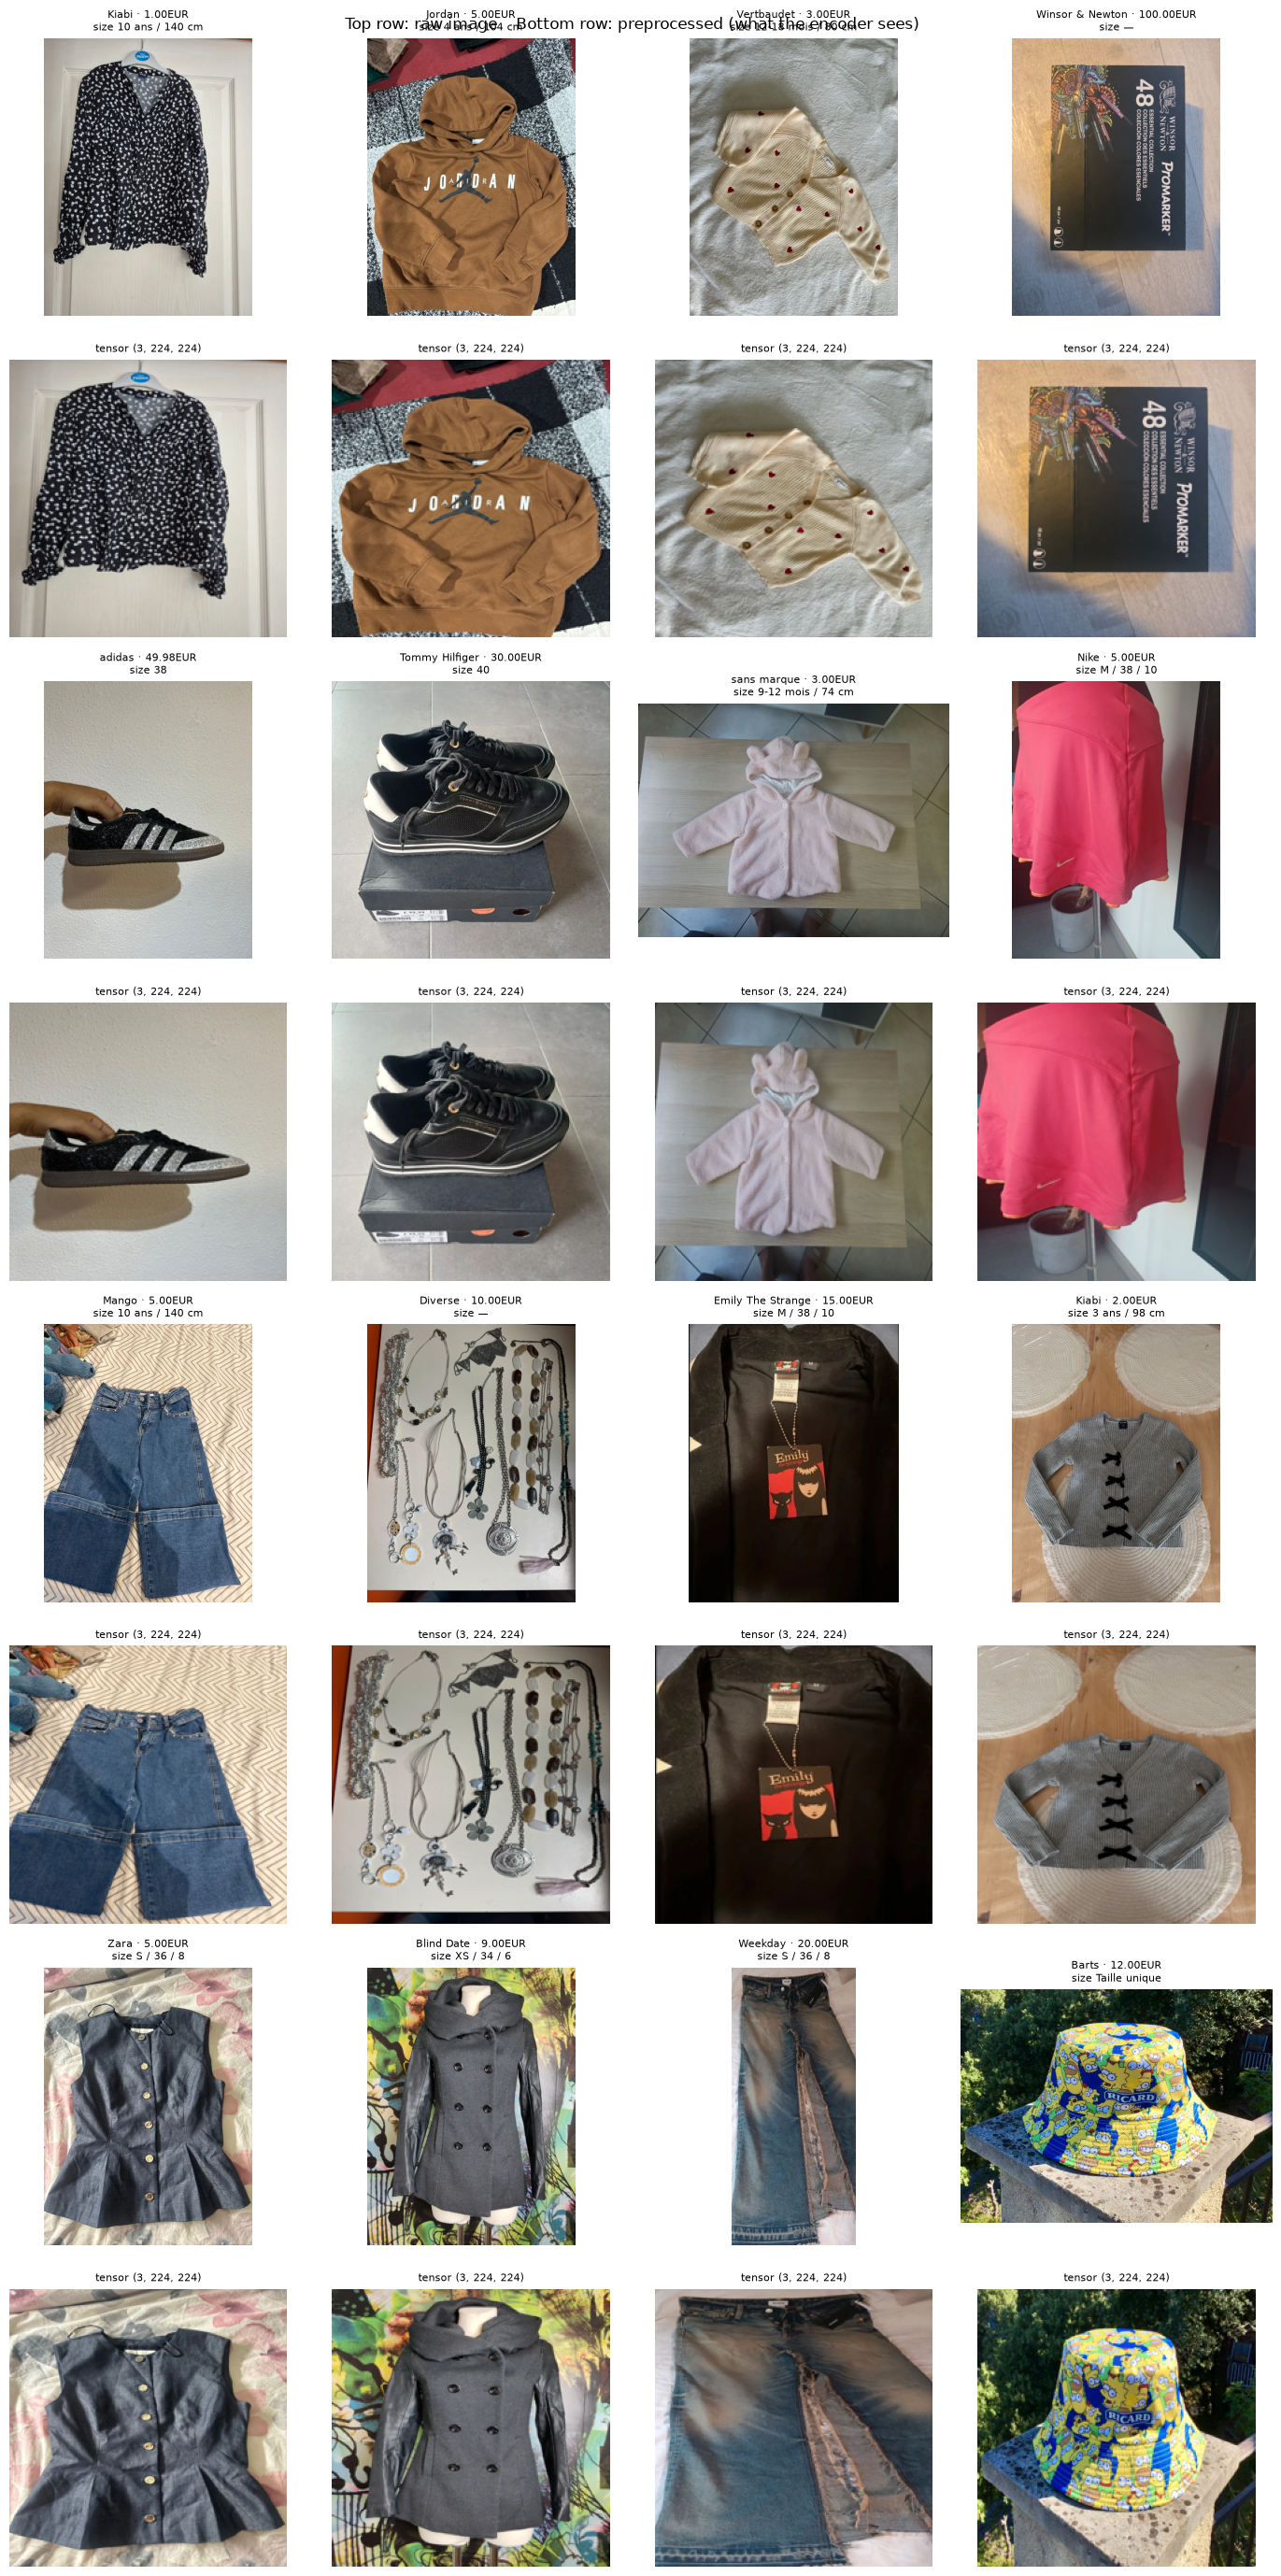

In [13]:
def tensor_to_displayable(t: torch.Tensor) -> np.ndarray:
    """Undo SigLIP normalisation (mean=0.5, std=0.5) for display."""
    mean = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
    std  = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
    img = (t * std + mean).clamp(0, 1)
    return img.permute(1, 2, 0).numpy()


valid = [(p, img) for p, img in zip(products, raw_images) if img is not None][:N_SAMPLES]

cols = 4
rows = (len(valid) + cols - 1) // cols
fig, axes = plt.subplots(rows * 2, cols, figsize=(cols * 3.5, rows * 7))
fig.suptitle("Top row: raw image    Bottom row: preprocessed (what the encoder sees)", fontsize=12)

for idx, (prod, raw) in enumerate(valid):
    r, c = divmod(idx, cols)
    ax_raw  = axes[r * 2][c]
    ax_pre  = axes[r * 2 + 1][c]

    # Raw image
    ax_raw.imshow(raw)
    ax_raw.set_title(f"{prod.brand or '—'} · {prod.price}{prod.currency}\nsize {prod.size or '—'}", fontsize=8)
    ax_raw.axis("off")

    # Preprocessed tensor (what the model actually ingests)
    tensor = preprocess(raw)          # shape (3, H, W), normalised
    ax_pre.imshow(tensor_to_displayable(tensor))
    ax_pre.set_title(f"tensor {tuple(tensor.shape)}", fontsize=8)
    ax_pre.axis("off")

# Hide unused axes
for idx in range(len(valid), rows * cols):
    r, c = divmod(idx, cols)
    axes[r * 2][c].axis("off")
    axes[r * 2 + 1][c].axis("off")

plt.tight_layout()
plt.show()

## 4 — Run the encoder and inspect output vectors

Output shape : (16, 768)
Vector norms : [1.         1.         1.0000001  1.         1.         1.
 1.         1.         0.99999994 1.         1.         0.99999994
 1.         1.         1.         1.        ]
Value range  : [-0.1523, 0.4321]


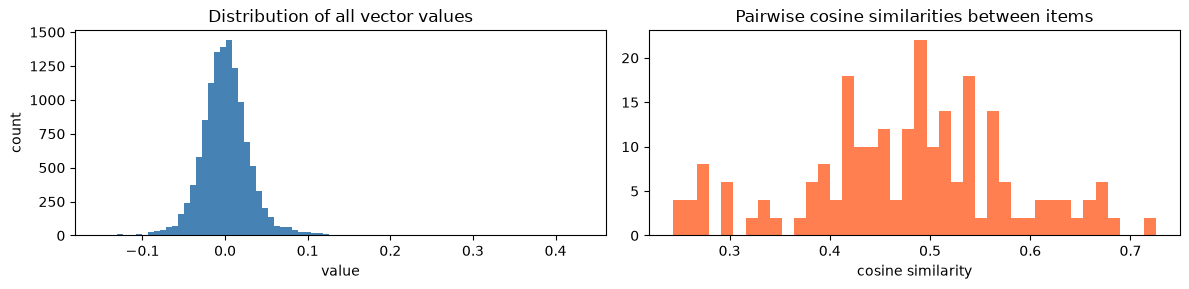

In [14]:
tensors = torch.stack([preprocess(img) for _, img in valid])   # (N, 3, H, W)

with torch.no_grad():
    features = model.encode_image(tensors)

vectors = F.normalize(features, p=2, dim=-1).cpu().numpy()

print(f"Output shape : {vectors.shape}")
print(f"Vector norms : {np.linalg.norm(vectors, axis=1)}")   # should all be ~1.0
print(f"Value range  : [{vectors.min():.4f}, {vectors.max():.4f}]")

# Distribution of activations across the batch
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].hist(vectors.flatten(), bins=80, color="steelblue", edgecolor="none")
axes[0].set_title("Distribution of all vector values")
axes[0].set_xlabel("value"); axes[0].set_ylabel("count")

cos_sim = vectors @ vectors.T
mask = ~np.eye(len(vectors), dtype=bool)
axes[1].hist(cos_sim[mask].flatten(), bins=40, color="coral", edgecolor="none")
axes[1].set_title("Pairwise cosine similarities between items")
axes[1].set_xlabel("cosine similarity")

plt.tight_layout()
plt.show()

## 5 — PCA map of all stored Qdrant vectors

Total vectors fetched: 1988
PCA explained variance: 10.4%


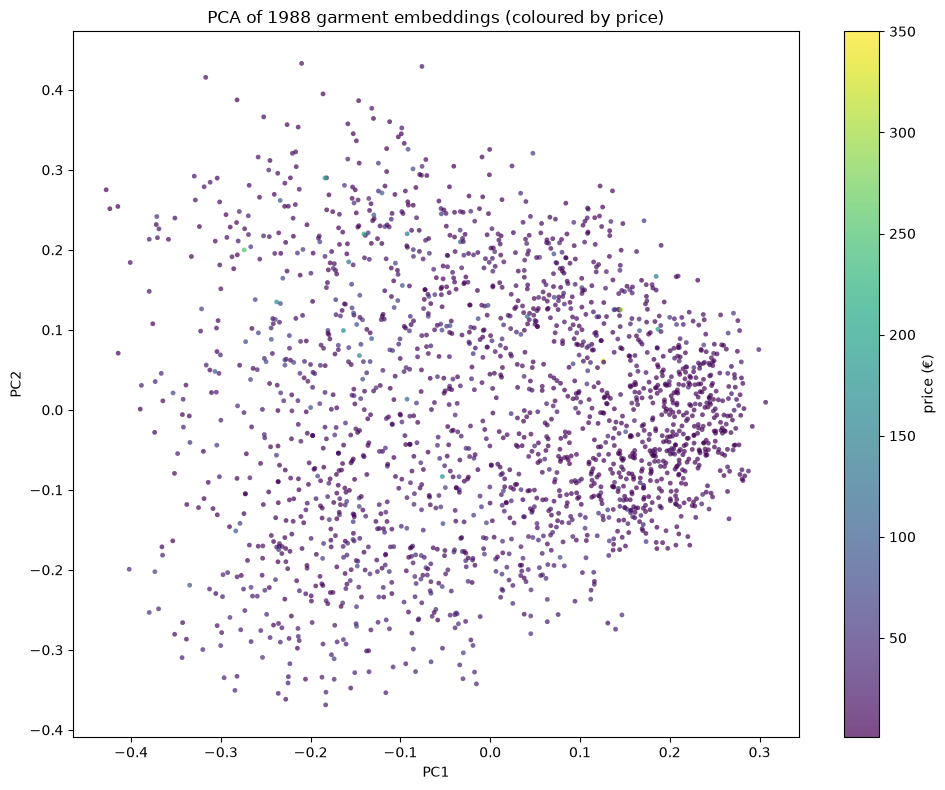

In [15]:
from sklearn.decomposition import PCA
from MedClip_pipeline.embeddings.vector_store import COLLECTION_NAME, get_client

qdrant = get_client()

# Scroll through all points and collect vectors + payloads
all_vecs, all_brands, all_prices = [], [], []
offset = None
while True:
    batch, offset = qdrant.scroll(
        collection_name=COLLECTION_NAME,
        with_vectors=True,
        with_payload=True,
        limit=100,
        offset=offset,
    )
    if not batch:
        break
    for pt in batch:
        all_vecs.append(pt.vector)
        all_brands.append((pt.payload or {}).get("brand") or "unknown")
        all_prices.append(float((pt.payload or {}).get("price", 0) or 0))
    if offset is None:
        break

vecs_np = np.array(all_vecs, dtype="float32")
print(f"Total vectors fetched: {len(vecs_np)}")

pca = PCA(n_components=2)
coords = pca.fit_transform(vecs_np)
print(f"PCA explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(
    coords[:, 0], coords[:, 1],
    c=all_prices, cmap="viridis", s=12, alpha=0.7, linewidths=0
)
plt.colorbar(scatter, ax=ax, label="price (€)")
ax.set_title(f"PCA of {len(vecs_np)} garment embeddings (coloured by price)")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 6 — Inspect nearest neighbours for a specific item

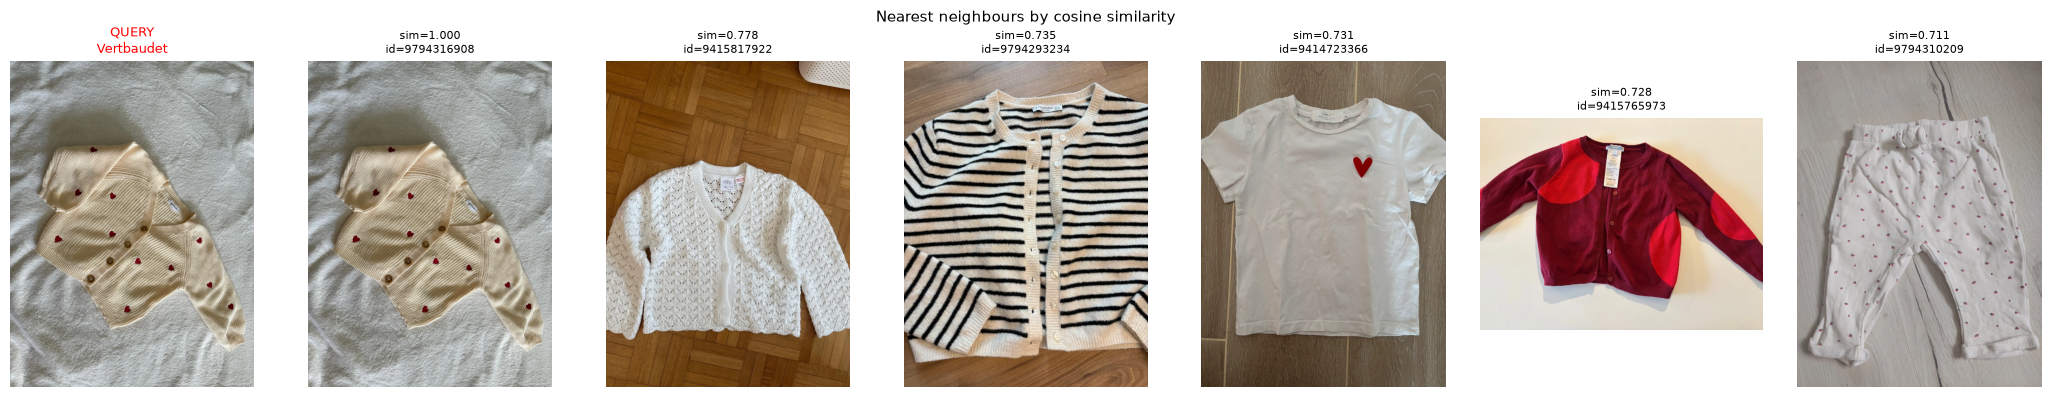

In [24]:
# Pick any product id from the list above
QUERY_IDX = 2 # index into `valid` list

query_vec = vectors[QUERY_IDX].tolist()
query_prod, query_img = valid[QUERY_IDX]

neighbours = qdrant.query_points(
    collection_name=COLLECTION_NAME,
    query=query_vec,
    limit=6,
).points

# Download neighbour images
async def fetch_by_ids(ids):
    results = qdrant.retrieve(
        collection_name=COLLECTION_NAME,
        ids=ids,
        with_payload=True,
    )
    urls = [(r.id, (r.payload or {}).get("image_url", "")) for r in results]
    imgs = {}
    async with AsyncSession(impersonate="chrome124") as http:
        for rid, url in urls:
            try:
                resp = await http.get(url)
                imgs[rid] = Image.open(BytesIO(resp.content)).convert("RGB")
            except:
                imgs[rid] = None
    return imgs, dict(urls)

nb_imgs, nb_urls = await fetch_by_ids([n.id for n in neighbours])

fig, axes = plt.subplots(1, len(neighbours) + 1, figsize=((len(neighbours) + 1) * 3, 4))
axes[0].imshow(query_img)
axes[0].set_title(f"QUERY\n{query_prod.brand or '—'}", fontsize=9, color="red")
axes[0].axis("off")

for i, nb in enumerate(neighbours):
    img = nb_imgs.get(nb.id)
    if img:
        axes[i + 1].imshow(img)
    axes[i + 1].set_title(f"sim={nb.score:.3f}\nid={nb.id}", fontsize=8)
    axes[i + 1].axis("off")

plt.suptitle("Nearest neighbours by cosine similarity", fontsize=11)
plt.tight_layout()
plt.show()